# Activity 1: Multiple Linear Regression
**Course:** Regression and Classification Algorithms (RCA)  
**Roll No.:** AD3270  
**Role:** Data analyst at a real-estate organisation  
**Dataset:** Ames Housing (2,930 house sales; 82 columns)

**Dataset link:** https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset
## 1. Problem statement
The organisation wants to estimate a house's sale price to support an initial property valuation. The target is `SalePrice` (US dollars). I use three numerical inputs: `Gr Liv Area` (above-ground living area, square feet), `Overall Qual` (overall material/finish rating, 1–10) and `Year Built` (year of construction). These features are plausible price drivers. The model estimates associations, not causal effects.

**Success measure:** compare the multiple-feature model with a single-feature model and a mean-price baseline on an untouched 20% test set. Lower MAE/RMSE and higher test R² are better.

## 2. Import libraries and load data

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.max_columns", 100)

In [26]:

df = pd.read_csv("AmesHousing.csv")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


## 3. Understand and check the data
One row represents one house sale. The full file contains 2,930 rows and 82 columns. The three selected inputs and target are numerical; `Order` and `PID` are identifiers and are not used as predictors.

In [27]:
print("Data types:")
display(df.dtypes.value_counts().rename("Number of columns").to_frame())
print("Summary statistics for selected columns:")
display(df[["Gr Liv Area", "Overall Qual", "Year Built", "SalePrice"]].describe())
print("Missing values in selected columns:")
display(df[["Gr Liv Area", "Overall Qual", "Year Built", "SalePrice"]].isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Data types:


,Number of columns
object,43
int64,28
float64,11


Summary statistics for selected columns:


,Gr Liv Area,Overall Qual,Year Built,SalePrice
count,2930.000000,2930.000000,2930.000000,2930.000000
mean,1499.690444,6.094881,1971.356314,180796.060068
std,505.508887,1.411026,30.245361,79886.692357
min,334.000000,1.000000,1872.000000,12789.000000
25%,1126.000000,5.000000,1954.000000,129500.000000
50%,1442.000000,6.000000,1973.000000,160000.000000
75%,1742.750000,7.000000,2001.000000,213500.000000
max,5642.000000,10.000000,2010.000000,755000.000000


Missing values in selected columns:


,0
Gr Liv Area,0
Overall Qual,0
Year Built,0
SalePrice,0


Duplicate rows: 0


In [28]:
features = ["Gr Liv Area", "Overall Qual", "Year Built"]
target = "SalePrice"
data = df[features + [target]].dropna().copy()
print("Rows before cleaning:", len(df))
print("Rows after removing missing selected values:", len(data))
print("Rows removed:", len(df) - len(data))
print("Exact duplicate full records in original file:", df.duplicated().sum())
print("Note: repeated values across selected columns can be legitimate separate house sales.")
display(data.head())

Rows before cleaning: 2930
Rows after removing missing selected values: 2930
Rows removed: 0
Exact duplicate full records in original file: 0
Note: repeated values across selected columns can be legitimate separate house sales.


,Gr Liv Area,Overall Qual,Year Built,SalePrice
0,1656,6,1960,215000
1,896,5,1961,105000
2,1329,6,1958,172000
3,2110,7,1968,244000
4,1629,5,1997,189900


## 4. Explore relationships before modelling

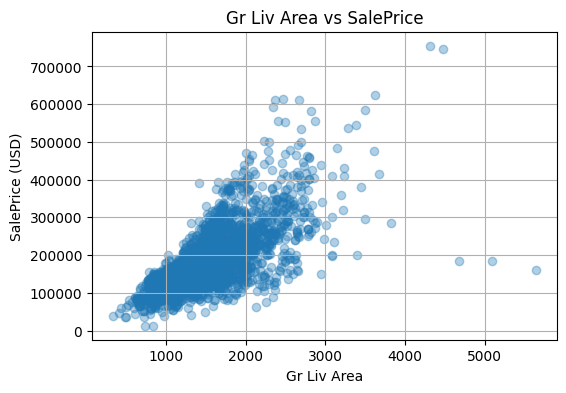

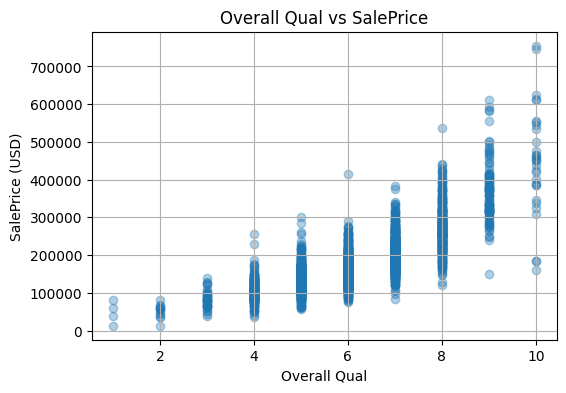

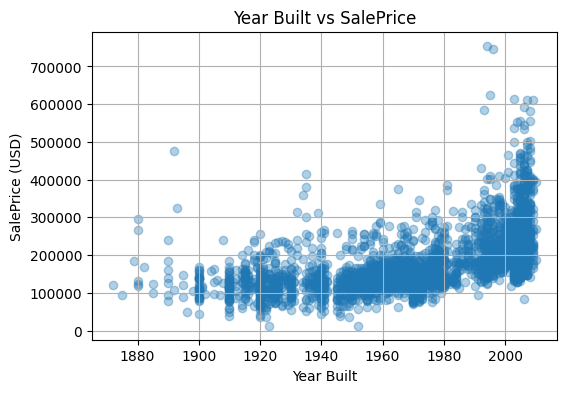

In [29]:
for col in features:
    plt.figure(figsize=(6, 4))
    plt.scatter(data[col], data[target], alpha=0.35)
    plt.title(f"{col} vs SalePrice")
    plt.xlabel(col)
    plt.ylabel("SalePrice (USD)")
    plt.grid(True)
    plt.show()

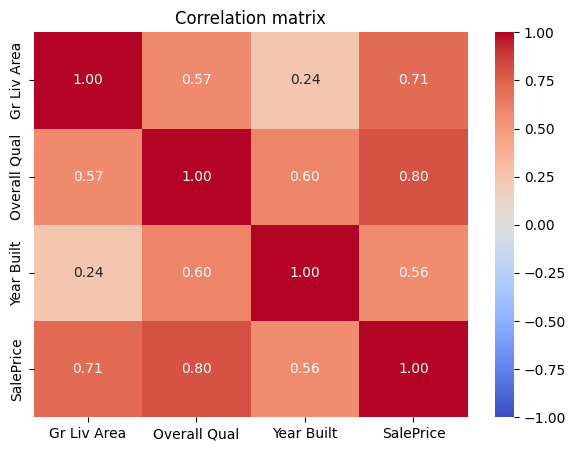

,Gr Liv Area,Overall Qual,Year Built,SalePrice
Gr Liv Area,1.000000,0.570556,0.241726,0.706780
Overall Qual,0.570556,1.000000,0.597027,0.799262
Year Built,0.241726,0.597027,1.000000,0.558426
SalePrice,0.706780,0.799262,0.558426,1.000000


In [30]:
corr = data[features + [target]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()
display(corr)

### Interpretation of Correlation Heatmap

The correlation matrix shows the relationship between the input features and the target variable SalePrice.

1. **Gr Liv Area and SalePrice (0.707):** There is a strong positive correlation. This indicates that houses with larger living areas generally have higher sale prices.

2. **Overall Qual and SalePrice (0.799):** This has the strongest positive correlation with SalePrice. It indicates that houses with better overall material and finish quality generally have higher sale prices.

3. **Year Built and SalePrice (0.558):** There is a moderate positive correlation. This suggests that newer houses generally tend to have higher sale prices.

4. **Correlation among input features:** Overall Qual and Year Built have a correlation of 0.597, while Gr Liv Area and Overall Qual have a correlation of 0.571. These relationships should be considered when checking multicollinearity.

**Conclusion:** Overall Qual has the strongest linear relationship with SalePrice, so it is selected as the single-feature baseline.

Correlation indicates association, not causation. A high correlation does not prove that one variable directly causes a change in another.

## 5. Manual least-squares calculation (two features)


In [31]:
sample = data[["Gr Liv Area", "Overall Qual", "SalePrice"]].head(6).copy()
display(sample)
X_small = np.column_stack([np.ones(len(sample)), sample["Gr Liv Area"], sample["Overall Qual"]])
y_small = sample["SalePrice"].to_numpy()

print("Design matrix X:")
display(pd.DataFrame(X_small, columns=["1 (intercept)", "X1: Gr Liv Area", "X2: Overall Qual"]))
print("Target vector y:")
display(pd.DataFrame(y_small, columns=["SalePrice"]))

,Gr Liv Area,Overall Qual,SalePrice
0,1656,6,215000
1,896,5,105000
2,1329,6,172000
3,2110,7,244000
4,1629,5,189900
5,1604,6,195500


Design matrix X:


,1 (intercept),X1: Gr Liv Area,X2: Overall Qual
0,1.0,1656.0,6.0
1,1.0,896.0,5.0
2,1.0,1329.0,6.0
3,1.0,2110.0,7.0
4,1.0,1629.0,5.0
5,1.0,1604.0,6.0


Target vector y:


,SalePrice
0,215000
1,105000
2,172000
3,244000
4,189900
5,195500


In [46]:
# Step 1: Calculate X transpose X
XTX = X_small.T @ X_small

# Step 2: Calculate X transpose y
XTy = X_small.T @ y_small

print("X transpose X:")
display(pd.DataFrame(XTX))

print("X transpose y:")
display(pd.DataFrame(XTy, columns=["XTy"]))

# Step 3: Calculate inverse of XTX
XTX_inverse = np.linalg.inv(XTX)

print("Inverse of XTX:")
display(pd.DataFrame(XTX_inverse))

# Step 4: Apply normal equation
# b = (XTX)^-1 XTy

b_manual = XTX_inverse @ XTy

print("Manual coefficients:")
print("b0 =", b_manual[0])
print("b1 =", b_manual[1])
print("b2 =", b_manual[2])

# Step 5: Write the regression equation
print("\nRegression Equation:")
print(
    f"SalePrice = {b_manual[0]:.2f}"
    f" + ({b_manual[1]:.2f} * Gr Liv Area)"
    f" + ({b_manual[2]:.2f} * Overall Qual)"
)

X transpose X:


,0,1,2
0,6.0,9224.0,35.0
1,9224.0,14989950.0,54929.0
2,35.0,54929.0,207.0


X transpose y:


,XTy
0,1.121400e+06
1,1.816477e+09
2,6.677500e+06


Inverse of XTX:


,0,1,2
0,13.814981,0.002119,-2.898082
1,0.002119,0.000003,-0.001085
2,-2.898082,-0.001085,0.782816


Manual coefficients:
b0 = -11234.1195405379
b1 = 105.85836828256122
b2 = 6067.6322344256705

Regression Equation:
SalePrice = -11234.12 + (105.86 * Gr Liv Area) + (6067.63 * Overall Qual)


In [33]:
# Verify with sklearn using exactly the same six rows and two features
small_model = LinearRegression()
small_model.fit(sample[["Gr Liv Area", "Overall Qual"]], y_small)
print("Library intercept:", small_model.intercept_)
print("Library coefficients:", small_model.coef_)
print("Difference from manual coefficients:",
      np.r_[small_model.intercept_, small_model.coef_] - b_manual)

# Predict the first sample row and calculate its residual (actual - predicted)
one_X = sample[["Gr Liv Area", "Overall Qual"]].iloc[[0]]
one_actual = sample["SalePrice"].iloc[0]
one_pred = small_model.predict(one_X)[0]
print("First sample actual:", one_actual)
print("First sample prediction:", round(one_pred, 2))
print("First sample residual:", round(one_actual - one_pred, 2))

Library intercept: -11234.119540539687
Library coefficients: [ 105.85836828 6067.63223443]
Difference from manual coefficients: [-1.22599886e-09 -2.27373675e-13  2.70119926e-10]
First sample actual: 215000
First sample prediction: 200473.13
First sample residual: 14526.87


### Manual Calculation and Library Verification

The manual calculation uses six observations and two input features: Gr Liv Area and Overall Qual.

The calculated coefficients are:

- Intercept (b0): -11234.12
- Coefficient (b1): 105.86
- Coefficient (b2): 6067.63

The fitted equation is:

SalePrice = -11234.12 + 105.86(Gr Liv Area) + 6067.63(Overall Qual)

The coefficients obtained manually are almost identical to those obtained using the Scikit-learn LinearRegression library. The tiny differences are caused by floating-point rounding.

For the first observation:

- Actual SalePrice = $215,000
- Predicted SalePrice = $200,473.13
- Residual = Actual - Predicted = $14,526.87

The positive residual indicates that the model under-predicted the actual house sale price by approximately $14,526.87.

This verifies that the manual normal-equation calculation and the library implementation give consistent results.

## 6. Train/test split and baseline models

In [34]:
X = data[features]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Total observations:", len(data))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Total observations: 2930
Training observations: 2344
Testing observations: 586


**Validation decision:** the test set is held back until final evaluation. The same fixed split is used for both models. Ordinary least squares does not require scaling, so the models use the original feature units and coefficients remain easy to interpret.

In [35]:
# Choose the single input most strongly correlated with SalePrice
best_feature = data[features].corrwith(data[target]).abs().idxmax()
print("Single-feature baseline input:", best_feature)

single_model = LinearRegression()
single_model.fit(X_train[[best_feature]], y_train)

multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

print("Single model intercept:", single_model.intercept_)
print("Single model coefficient:", single_model.coef_[0])
print("Multiple model intercept:", multiple_model.intercept_)
display(pd.DataFrame({"Feature": features, "Coefficient": multiple_model.coef_}))

Single-feature baseline input: Overall Qual
Single model intercept: -89311.54045190802
Single model coefficient: 44174.67082794741
Multiple model intercept: -1067424.844632082


,Feature,Coefficient
0,Gr Liv Area,61.626687
1,Overall Qual,25249.813536
2,Year Built,507.931044


## 7. Full multiple regression equation and coefficient meaning

In [36]:
equation = f"SalePrice = {multiple_model.intercept_:.2f}"
for name, coef in zip(features, multiple_model.coef_):
    equation += f" + ({coef:.2f} * {name})"
print(equation)

SalePrice = -1067424.84 + (61.63 * Gr Liv Area) + (25249.81 * Overall Qual) + (507.93 * Year Built)


### Interpretation of Multiple Linear Regression Coefficients

The fitted multiple regression equation is:

SalePrice = -1067424.84 + 61.63(Gr Liv Area) + 25249.81(Overall Qual) + 507.93(Year Built)

The coefficients are interpreted as follows:

1. **Gr Liv Area (61.63):** Keeping Overall Qual and Year Built constant, an increase of one square foot in living area is associated with an estimated increase of $61.63 in SalePrice.

2. **Overall Qual (25249.81):** Keeping the other features constant, an increase of one quality rating point is associated with an estimated increase of $25,249.81 in SalePrice.

3. **Year Built (507.93):** Keeping the other features constant, an increase of one year in the construction year is associated with an estimated increase of $507.93 in SalePrice.

4. **Intercept (-1067424.84):** This is the predicted SalePrice when all three input features are zero. This situation is unrealistic for an actual house, so the intercept has limited practical meaning.

### Standardised Coefficients

Standardised coefficients allow comparison of feature contributions on a common scale.

- Gr Liv Area: 0.403
- Overall Qual: 0.455
- Year Built: 0.200

Overall Qual has the largest standardised coefficient, followed by Gr Liv Area and Year Built.

These coefficients describe relationships within the fitted model and do not establish causation.

In [37]:
# Standardised coefficients for comparing relative scale
X_train_std = (X_train - X_train.mean()) / X_train.std()
y_train_std = (y_train - y_train.mean()) / y_train.std()
std_model = LinearRegression().fit(X_train_std, y_train_std)
display(pd.DataFrame({
    "Feature": features,
    "Standardised coefficient": std_model.coef_
}))

,Feature,Standardised coefficient
0,Gr Liv Area,0.403216
1,Overall Qual,0.454584
2,Year Built,0.199823


## 8. Test predictions and regression metrics

In [38]:
single_pred = single_model.predict(X_test[[best_feature]])
multiple_pred = multiple_model.predict(X_test)

def regression_metrics(actual, predicted, p):
    n = len(actual)
    mse = mean_squared_error(actual, predicted)
    r2 = r2_score(actual, predicted)
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2,
        "Adjusted R2": adjusted_r2
    }

# Mean baseline: predict the training-set average for every test house
mean_pred = np.full(len(y_test), y_train.mean())
mean_metrics = regression_metrics(y_test, mean_pred, 0)
single_metrics = regression_metrics(y_test, single_pred, 1)
multiple_metrics = regression_metrics(y_test, multiple_pred, len(features))
results = pd.DataFrame(
    [mean_metrics, single_metrics, multiple_metrics],
    index=["Training-mean baseline", "Single feature", "Multiple features"]
)
display(results.round(3))

,MAE,MSE,RMSE,R2,Adjusted R2
Training-mean baseline,64611.412,8.140076e+09,90222.372,-0.015,-0.015
Single feature,36141.272,2.796155e+09,52878.678,0.651,0.651
Multiple features,29135.301,1.957403e+09,44242.551,0.756,0.755


### Interpretation of Regression Evaluation Metrics

The model is evaluated on the test dataset, which contains 586 observations.

- **MAE:** The multiple-feature model has an average absolute prediction error of approximately $29,135.30. This is lower than the single-feature model's $36,141.27.

- **MSE:** The multiple-feature model has an MSE of approximately 1.957 billion, compared with 2.796 billion for the single-feature model. This indicates fewer large squared prediction errors overall.

- **RMSE:** The multiple-feature model has an RMSE of approximately $44,242.55, which is lower than the single-feature model's $52,878.68.

- **R²:** The multiple-feature model achieves 0.756, compared with 0.651 for the single-feature model. It explains approximately 75.6% of the variation in test-set house prices.

- **Adjusted R²:** The multiple-feature model achieves 0.755, showing that its improvement remains after accounting for the number of predictors.

### Model Comparison Conclusion

The multiple-feature model performs better than the single-feature model because it has lower MAE, MSE and RMSE and higher R² and adjusted R².

The training-mean baseline has a negative test R² of approximately -0.015, meaning it performs slightly worse than predicting the test-set mean.

Therefore, adding Gr Liv Area and Year Built to the Overall Qual model improves prediction performance enough to justify the additional complexity.

In [39]:
prediction_table = pd.DataFrame({
    "Actual SalePrice (USD)": y_test,
    "Single-feature prediction (USD)": single_pred,
    "Multiple-feature prediction (USD)": multiple_pred
})
display(prediction_table.head(10).round(2))

,Actual SalePrice (USD),Single-feature prediction (USD),Multiple-feature prediction (USD)
1357,161000,264085.83,215010.98
2367,116000,175736.48,149189.54
2822,196500,219911.16,232954.14
2126,123600,87387.14,107399.33
1544,126000,175736.48,118984.15
2415,174190,175736.48,184700.70
2227,200000,264085.83,207199.80
410,148500,175736.48,177474.24
761,88750,87387.14,65393.41
436,409900,264085.83,309290.52


## 9. Residual analysis and regression assumptions

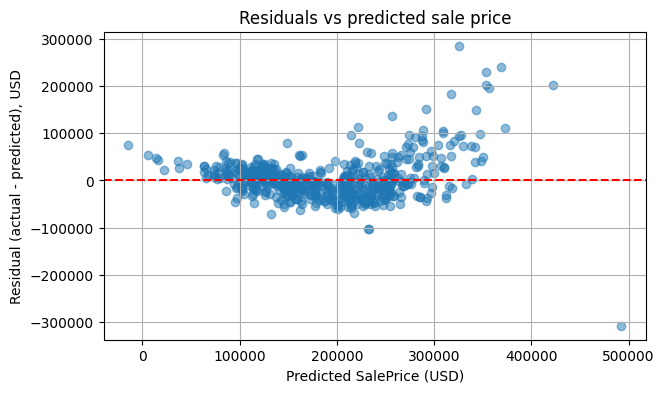

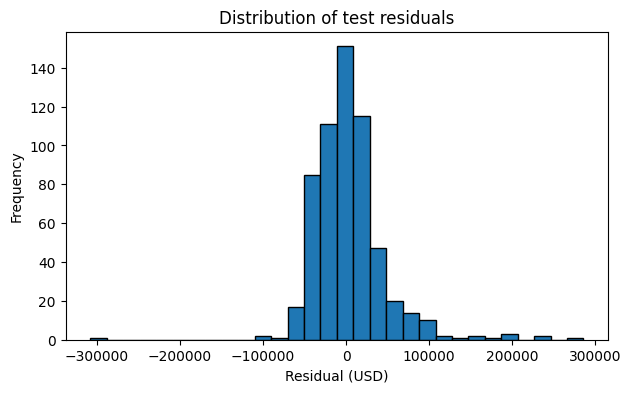

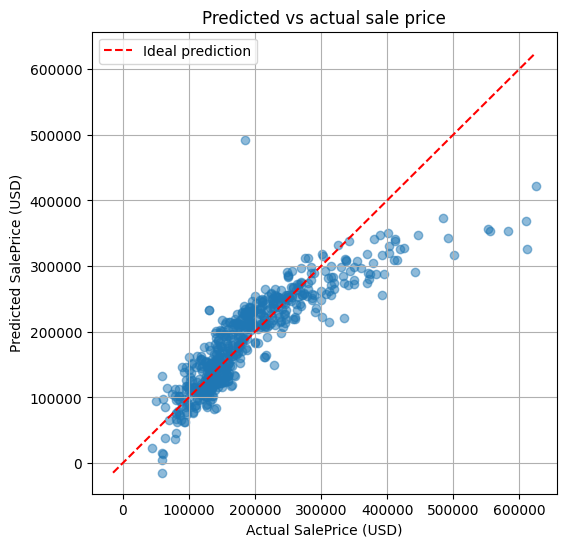

In [40]:
residuals = y_test - multiple_pred

plt.figure(figsize=(7, 4))
plt.scatter(multiple_pred, residuals, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals vs predicted sale price")
plt.xlabel("Predicted SalePrice (USD)")
plt.ylabel("Residual (actual - predicted), USD")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(residuals, bins=30, edgecolor="black")
plt.title("Distribution of test residuals")
plt.xlabel("Residual (USD)")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_test, multiple_pred, alpha=0.5)
low = min(y_test.min(), multiple_pred.min())
high = max(y_test.max(), multiple_pred.max())
plt.plot([low, high], [low, high], "r--", label="Ideal prediction")
plt.title("Predicted vs actual sale price")
plt.xlabel("Actual SalePrice (USD)")
plt.ylabel("Predicted SalePrice (USD)")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
# Residual summary
print("Residual Mean:", round(residuals.mean(), 2))
print("Residual Standard Deviation:", round(residuals.std(), 2))
print("Residual Skewness:", round(residuals.skew(), 3))

print("\nResidual Summary:")
display(residuals.describe())

Residual Mean: 2961.41
Residual Standard Deviation: 44181.04
Residual Skewness: 1.238

Residual Summary:


,SalePrice
count,586.000000
mean,2961.414836
std,44181.040485
min,-307907.286155
25%,-22523.521437
50%,-1355.072662
75%,19519.153853
max,285714.566750


### Interpretation of Residual Analysis

Residuals are calculated by subtracting predicted values from actual values.

Residual = Actual SalePrice - Predicted SalePrice

1. **Residual Plot:** The residual plot helps identify whether prediction errors are randomly distributed around zero. A visible pattern or funnel shape may indicate non-linearity or unequal error variance.

2. **Residual Histogram:** The histogram helps examine the distribution of errors. A roughly symmetric distribution around zero would support the normality assumption. Skewness or extreme values may indicate departures from normality.

3. **Predicted vs Actual Plot:** Points closer to the ideal 45-degree line indicate more accurate predictions. Points farther away indicate larger prediction errors.

Residual analysis helps identify where the model performs poorly and which assumptions may need further investigation.

In [41]:
# Correlations among input features
display(X.corr())

X_with_constant = np.column_stack([np.ones(len(X)), X.values])
vif_table = pd.DataFrame({
    "Feature": X.columns,
    "VIF": [variance_inflation_factor(X_with_constant, i + 1)
            for i in range(X.shape[1])]
})
display(vif_table)


,Gr Liv Area,Overall Qual,Year Built
Gr Liv Area,1.000000,0.570556,0.241726
Overall Qual,0.570556,1.000000,0.597027
Year Built,0.241726,0.597027,1.000000


,Feature,VIF
0,Gr Liv Area,1.516843
1,Overall Qual,2.219242
2,Year Built,1.589691


### Interpretation of Correlation and VIF

Multicollinearity occurs when two or more independent variables are highly correlated with each other.

The correlation matrix shows:

- Gr Liv Area and Overall Qual: 0.571
- Gr Liv Area and Year Built: 0.242
- Overall Qual and Year Built: 0.597

The VIF values are:

- Gr Liv Area: 1.517
- Overall Qual: 2.219
- Year Built: 1.590

All VIF values are below 5, indicating that there is no serious multicollinearity among the selected features based on this check.

Overall Qual has the highest VIF, but its value is still relatively low.

Therefore, all three selected features are retained in the model. No feature needs to be removed because of severe multicollinearity.

### Assumptions of Multiple Linear Regression

1. **Linearity:** Linear regression assumes that the relationship between the input features and SalePrice can be reasonably represented by a linear equation. Scatter plots are used to inspect these relationships. Some non-linear patterns may still exist.

2. **Independence of Errors:** The errors should be independent of one another. Since the dataset contains separate house sales, independence is a reasonable working assumption, but it has not been formally tested.

3. **Constant Variance (Homoscedasticity):** The residuals should have approximately constant variance across predicted values. The residual plot should be examined for a funnel-shaped pattern. Unequal error spread may indicate heteroscedasticity.

4. **Normality of Errors:** Residuals should be approximately normally distributed, especially for conventional statistical inference. The histogram helps assess this assumption. Skewness and extreme residuals may indicate departures from normality.

5. **No Severe Multicollinearity:** Input features should not be excessively correlated. The correlation matrix and VIF values show that all selected features have VIF values below 5, suggesting no serious multicollinearity.

**Conclusion:** The multicollinearity check is satisfactory. Linearity, constant variance and normality require consideration based on the diagnostic plots. Independence remains an assumption rather than a proven result. These limitations should be considered when using the model for house price estimation.

## 10. Predict a new example

In [42]:
# Use typical values from the training data; these are within the observed feature ranges.
new_house = pd.DataFrame([X_train.median().to_dict()])
new_price = multiple_model.predict(new_house)[0]
display(new_house)
print("Estimated SalePrice (USD):", round(new_price, 2))

,Gr Liv Area,Overall Qual,Year Built
0,1436.5,6.0,1972.0


Estimated SalePrice (USD): 174240.79


### Interpretation of New House Prediction

A new house example is created using the median values of the training features.

The selected input values are:

- Gr Liv Area: 1436.5 square feet
- Overall Qual: 6
- Year Built: 1972

The multiple linear regression model predicts the SalePrice to be approximately $174,240.79.

These values are based on the training dataset and fall within the observed feature ranges.

This prediction provides an estimated house price based on the selected characteristics. It is not a guaranteed market value.

# 11. Decision Log, Final Conclusion and Limitations

## Decision Log

| Decision | Reason |
|---|---|
| Dataset selection | Ames Housing contains numerical house features and continuous sale prices. |
| Features selected | Gr Liv Area, Overall Qual and Year Built are plausible factors associated with house prices. |
| Target selected | SalePrice is the continuous variable to be predicted. |
| Features removed | Other columns were excluded to keep the model focused; Order and PID are identifiers and were not used. |
| Missing values | Rows missing selected input or target values were removed. |
| Outliers | Retained because they may represent genuine house sales. |
| Train/test split | 80:20 split with random_state=42 to evaluate unseen data. |
| Model selection | Single-feature and multiple-feature Linear Regression models were compared. |
| Multicollinearity | Correlation matrix and VIF were used to check relationships among input features. |
| Evaluation | MAE, MSE, RMSE, R² and adjusted R² were calculated on test data. |

## Final Conclusion

In this activity, Multiple Linear Regression was implemented using the Ames Housing dataset to estimate house sale prices.

Three input features were selected: Gr Liv Area, Overall Qual and Year Built. The manual least-squares calculation was performed using two features and verified using the Scikit-learn LinearRegression library.

The multiple-feature model achieved a test R² of 0.756 and an adjusted R² of 0.755, while the single-feature model achieved a test R² of 0.651.

The multiple-feature model also produced lower MAE and RMSE, indicating better prediction performance on unseen data.

The VIF results indicate no serious multicollinearity among the selected features.

A new house example produced an estimated sale price of approximately $174,240.79.

## Limitations and Ethical Considerations

- House prices are also affected by location, neighbourhood, renovations and market conditions.
- The model uses only three input features, so it does not capture every factor influencing house prices.
- Linear Regression may not capture complex non-linear relationships.
- Residual analysis may reveal unequal error variance or non-normal errors.
- Predictions outside the observed feature ranges may be unreliable.
- The model should not be used as the sole basis for buying, selling, lending or official property valuation decisions.

A prediction is an estimate, not a guarantee. The model should be used as a supporting tool for initial property valuation rather than as a replacement for professional assessment.

In [49]:
# Save the cleaned dataset
data.to_csv('/content/processed_ames_housing.csv', index=False)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [50]:
from google.colab import files

files.download('/content/processed_ames_housing.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>